# Visualize stage-1 track SSMs on RGB

Pick a clip window with `START_IDX` + `SEQ_LEN`, run a stage-1 SSM
(`initiate` / `predict` / `update`) on either **noisy oracle** labels or
**model detections** (gated crops → heatmap + presence → `z, r_meas`), and
overlay **mean + covariance** on the real RGB frames.

Edit the control cell, then re-run from there.

- `MEAS_SOURCE = "oracle"` — Gaussian noise on `Label.csv` (legacy demo).
- `MEAS_SOURCE = "model"` — load `ARCH` from `checkpoints/`, closed-loop
  predict → uncertainty crop → detect → update. Crop size comes only from
  the tracker's covariance gate (no forced expand-on-miss).

`TRACKER` selects from `cv_kf`, `cv_akf`, `ca_akf`, `cv_ekf`, `ca_ekf`, `cv_pf`.
Adaptive filters learn `Q`/`R` online; `ca_*` use a 6D CA state
`[x,y,vx,vy,ax,ay]`; `*_ekf` add quadratic drag / optional gravity
(`tracker.ekf_drag` / `ekf_gravity`).


In [4]:
from __future__ import annotations

import math
from typing import Any, Callable

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Ellipse
import numpy as np
import torch

from horus.config import load_config, repo_root
from horus.convert.frame_diff import load_rgb
from horus.data.crop import crop_chw_stack
from horus.data.dataset import BallTrackDataset
from horus.data.index import index_clips
from horus.data.targets import scale_coords
from horus.eval import ARCH_REGISTRY, load_model
from horus.models import unpack_model_output
from horus.track import (
    TrackState,
    add_gaussian_noise,
    build_akf,
    build_ca_akf,
    build_ca_ekf,
    build_ekf,
    build_kf,
    build_pf,
    detection_to_measurement,
    gate_to_square_crop,
)

# =============================================================================
# Controls — edit, then re-run this cell and below
# =============================================================================
GAME = "game1"
CLIP = "Clip1"
START_IDX = 36          # first frame index in the clip
SEQ_LEN = 50            # number of frames to track / show
TRACKER = "ca_akf"      # "cv_kf" | "cv_akf" | "ca_akf" | "cv_ekf" | "ca_ekf" | "cv_pf"
MEAS_SOURCE = "model"   # "oracle" | "model"
ARCH = "event_frame_cnn"  # when MEAS_SOURCE="model"
CKPT_NAME = None          # e.g. "event_frame_cnn.pt"; None → checkpoints/<ARCH>.pt
SEED = 0                # noise / PF RNG; None = fresh each run
NOISE_SIGMA = None      # oracle only; px; None → tracker.r_meas
N_SIGMA = 3.0           # covariance ellipse / gate contour
NCOLS = 4               # RGB grid columns
# =============================================================================

ROOT = repo_root()
cfg = load_config()
W = int(cfg["image"]["width"])
H = int(cfg["image"]["height"])
src_w = int(cfg["source"]["width"])
src_h = int(cfg["source"]["height"])
buckets = [int(b) for b in (cfg.get("crop") or {}).get("buckets", [64, 128, 256])]
dcfg = cfg.get("detector") or {}
PRESENCE_THRESH = float(dcfg.get("presence_thresh", 0.5))
SHARPNESS_T = float(dcfg.get("sharpness_temperature", 0.1))
rng = np.random.default_rng(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def _build_pf(cfg):
    # Prefer notebook SEED for reproducible particle noise when set
    tcfg = dict(cfg.get("tracker") or {})
    if SEED is not None and tcfg.get("pf_seed") is None:
        tcfg["pf_seed"] = SEED
    return build_pf({**cfg, "tracker": tcfg})

TRACKER_BUILDERS: dict[str, Callable[[dict[str, Any]], Any]] = {
    "cv_kf": build_kf,
    "cv_akf": build_akf,
    "ca_akf": build_ca_akf,
    "cv_ekf": build_ekf,
    "ca_ekf": build_ca_ekf,
    "cv_pf": _build_pf,
}
if TRACKER not in TRACKER_BUILDERS:
    raise KeyError(f"Unknown TRACKER={TRACKER!r}; choose from {sorted(TRACKER_BUILDERS)}")
if MEAS_SOURCE not in ("oracle", "model"):
    raise KeyError(f"Unknown MEAS_SOURCE={MEAS_SOURCE!r}; choose 'oracle' or 'model'")

tracker = TRACKER_BUILDERS[TRACKER](cfg)
sigma = float(NOISE_SIGMA) if NOISE_SIGMA is not None else float(getattr(tracker, "r_meas", 5.0))

clips = {c.key: c for c in index_clips(cfg["paths"]["raw_dataset"])}
key = f"{GAME}/{CLIP}"
if key not in clips:
    raise KeyError(f"Clip not found: {key}")
clip = clips[key]
end_idx = START_IDX + SEQ_LEN
if START_IDX < 0 or end_idx > clip.num_frames:
    raise IndexError(
        f"Window [{START_IDX}, {end_idx}) out of range for {key} "
        f"(n_frames={clip.num_frames})"
    )

paths = clip.frames[START_IDX:end_idx]
labels = clip.labels[START_IDX:end_idx]
true_xy = np.zeros((SEQ_LEN, 2), dtype=np.float64)
visible = np.zeros(SEQ_LEN, dtype=bool)
for t, lb in enumerate(labels):
    visible[t] = lb.visibility != 0
    true_xy[t] = scale_coords(lb.x, lb.y, src_w, src_h, W, H)

rgbs = [load_rgb(str(p), W, H) for p in paths]

# Per-frame measurement / crop bookkeeping (shared by viz cells)
meas = np.full((SEQ_LEN, 2), np.nan, dtype=np.float64)
detected = np.zeros(SEQ_LEN, dtype=bool)
r_meas_t = np.full(SEQ_LEN, np.nan, dtype=np.float64)
crop_origins = np.full((SEQ_LEN, 2), -1, dtype=np.int64)
crop_sizes = np.zeros(SEQ_LEN, dtype=np.int64)
model = None
modality = None

if MEAS_SOURCE == "oracle":
    noisy = add_gaussian_noise(true_xy, sigma=sigma, rng=rng)
    for t in range(SEQ_LEN):
        if visible[t]:
            meas[t] = noisy[t]
            detected[t] = True
            r_meas_t[t] = sigma

    states: list[TrackState | None] = []
    state: TrackState | None = None
    for t in range(SEQ_LEN):
        if state is None:
            if detected[t]:
                state = tracker.initiate(meas[t])
            states.append(state)
            continue
        state = tracker.predict(state)
        state = tracker.update(state, meas[t] if detected[t] else None)
        states.append(state)

else:
    if ARCH not in ARCH_REGISTRY:
        raise KeyError(f"Unknown ARCH={ARCH!r}. Known: {sorted(ARCH_REGISTRY)}")
    _, modality = ARCH_REGISTRY[ARCH]
    ckpt_path = ROOT / "checkpoints" / (CKPT_NAME or f"{ARCH}.pt")
    if not ckpt_path.is_file():
        raise FileNotFoundError(f"Missing checkpoint: {ckpt_path}")

    model = load_model(ARCH, ckpt_path, device)
    model.eval()
    ckpt_meta = torch.load(ckpt_path, map_location="cpu", weights_only=True)
    snn_cfg = cfg.get("snn") or {}
    repeat_frame = bool(snn_cfg.get("repeat_frame", False)) if ARCH.endswith("_snn") else False
    input_steps = None
    if ARCH == "event_frame_snn":
        input_steps = int(ckpt_meta.get("steps", snn_cfg.get("steps") or cfg["sequence"]["length"]))

    # Full-frame modality stacks (crop disabled); gated crops applied in the loop.
    ds_cfg = load_config()
    ds_cfg.setdefault("crop", {})["enabled"] = False
    ds = BallTrackDataset(
        [clip],
        ds_cfg,
        modality,
        repeat_frame=repeat_frame,
        input_steps=input_steps,
        seed=SEED,
    )
    stacks_by_end: dict[int, torch.Tensor] = {}
    for i, ref in enumerate(ds.refs):
        if ref.clip_key != key:
            continue
        if START_IDX <= ref.end_idx < end_idx:
            stacks_by_end[ref.end_idx] = ds[i]["input"]

    missing = [START_IDX + t for t in range(SEQ_LEN) if (START_IDX + t) not in stacks_by_end]
    if missing:
        print(
            f"warning: no modality stack for {len(missing)} frame(s) "
            f"(need {ds.seq_len}-frame history); e.g. {missing[:5]}"
        )

    @torch.inference_mode()
    def detect_fn(
        crop: torch.Tensor, x0: int, y0: int, size: int
    ) -> tuple[torch.Tensor, torch.Tensor | float | None]:
        x = crop.detach().float().unsqueeze(0).to(device)
        heat, presence = unpack_model_output(model(x))
        heat = heat[0].detach().cpu()  # (1, h, w)
        if presence is None:
            return heat, None
        return heat, presence[0].detach().cpu()

    states = []
    state = None
    for t in range(SEQ_LEN):
        fi = START_IDX + t
        stack = stacks_by_end.get(fi)

        if state is None:
            # Bootstrap from first visible label (same as run_track_detect_loop z0).
            if visible[t]:
                state = tracker.initiate(true_xy[t])
                meas[t] = true_xy[t]
                detected[t] = True
                r_meas_t[t] = float(getattr(tracker, "r_meas", sigma))
            states.append(state)
            continue

        state = tracker.predict(state)
        if stack is None:
            state = tracker.update(state, None)
            states.append(state)
            continue

        x0, y0, size = gate_to_square_crop(
            state, buckets=buckets, img_w=W, img_h=H, n_sigma=N_SIGMA
        )
        crop_origins[t] = (x0, y0)
        crop_sizes[t] = size
        crop = crop_chw_stack(stack, x0, y0, size)
        heat, presence = detect_fn(crop, x0, y0, size)
        z, r = detection_to_measurement(
            heat,
            presence,
            origin=(x0, y0),
            presence_thresh=PRESENCE_THRESH,
            temperature=SHARPNESS_T,
        )
        if z is not None:
            meas[t] = z
            detected[t] = True
            r_meas_t[t] = float(r) if r is not None else np.nan
        state = tracker.update(state, z, r_meas=r)
        states.append(state)

tracked = [s is not None for s in states]
n_vis = int(visible.sum())
n_det = int(detected.sum())
print(
    f"{key}  frames[{START_IDX}:{end_idx}]  tracker={TRACKER}  "
    f"meas={MEAS_SOURCE}"
    + (f"/{ARCH}" if MEAS_SOURCE == "model" else f"  sigma={sigma:.1f}px")
    + f"  visible={n_vis}/{SEQ_LEN}  detected={n_det}/{SEQ_LEN}  "
    f"initiated={any(tracked)}"
)
if MEAS_SOURCE == "model":
    print(
        f"ckpt={(CKPT_NAME or f'{ARCH}.pt')}  modality={modality}  "
        f"device={device}  presence_thresh={PRESENCE_THRESH}  "
        f"n_crops={int((crop_sizes > 0).sum())}"
    )
    finite_r = r_meas_t[np.isfinite(r_meas_t) & (np.arange(SEQ_LEN) > 0)]
    if len(finite_r):
        print(f"model r_meas: mean={finite_r.mean():.2f}  median={np.median(finite_r):.2f} px")
if n_vis == 0:
    print("No visible labels in window — bump START_IDX or SEQ_LEN.")
if TRACKER in ("cv_akf", "ca_akf"):
    print(
        f"akf learned  r≈{float(np.sqrt(0.5*(tracker.R[0,0]+tracker.R[1,1]))):.2f}px  "
        f"tr(Q)={float(np.trace(tracker.Q)):.3g}  updates={tracker._update_count}"
    )


game1/Clip1  frames[36:86]  tracker=ca_akf  meas=model/event_frame_cnn  visible=46/50  detected=41/50  initiated=True
ckpt=event_frame_cnn.pt  modality=event_frame  device=cuda  presence_thresh=0.5  n_crops=49
model r_meas: mean=0.94  median=0.62 px
akf learned  r≈5.00px  tr(Q)=1.16e+03  updates=40


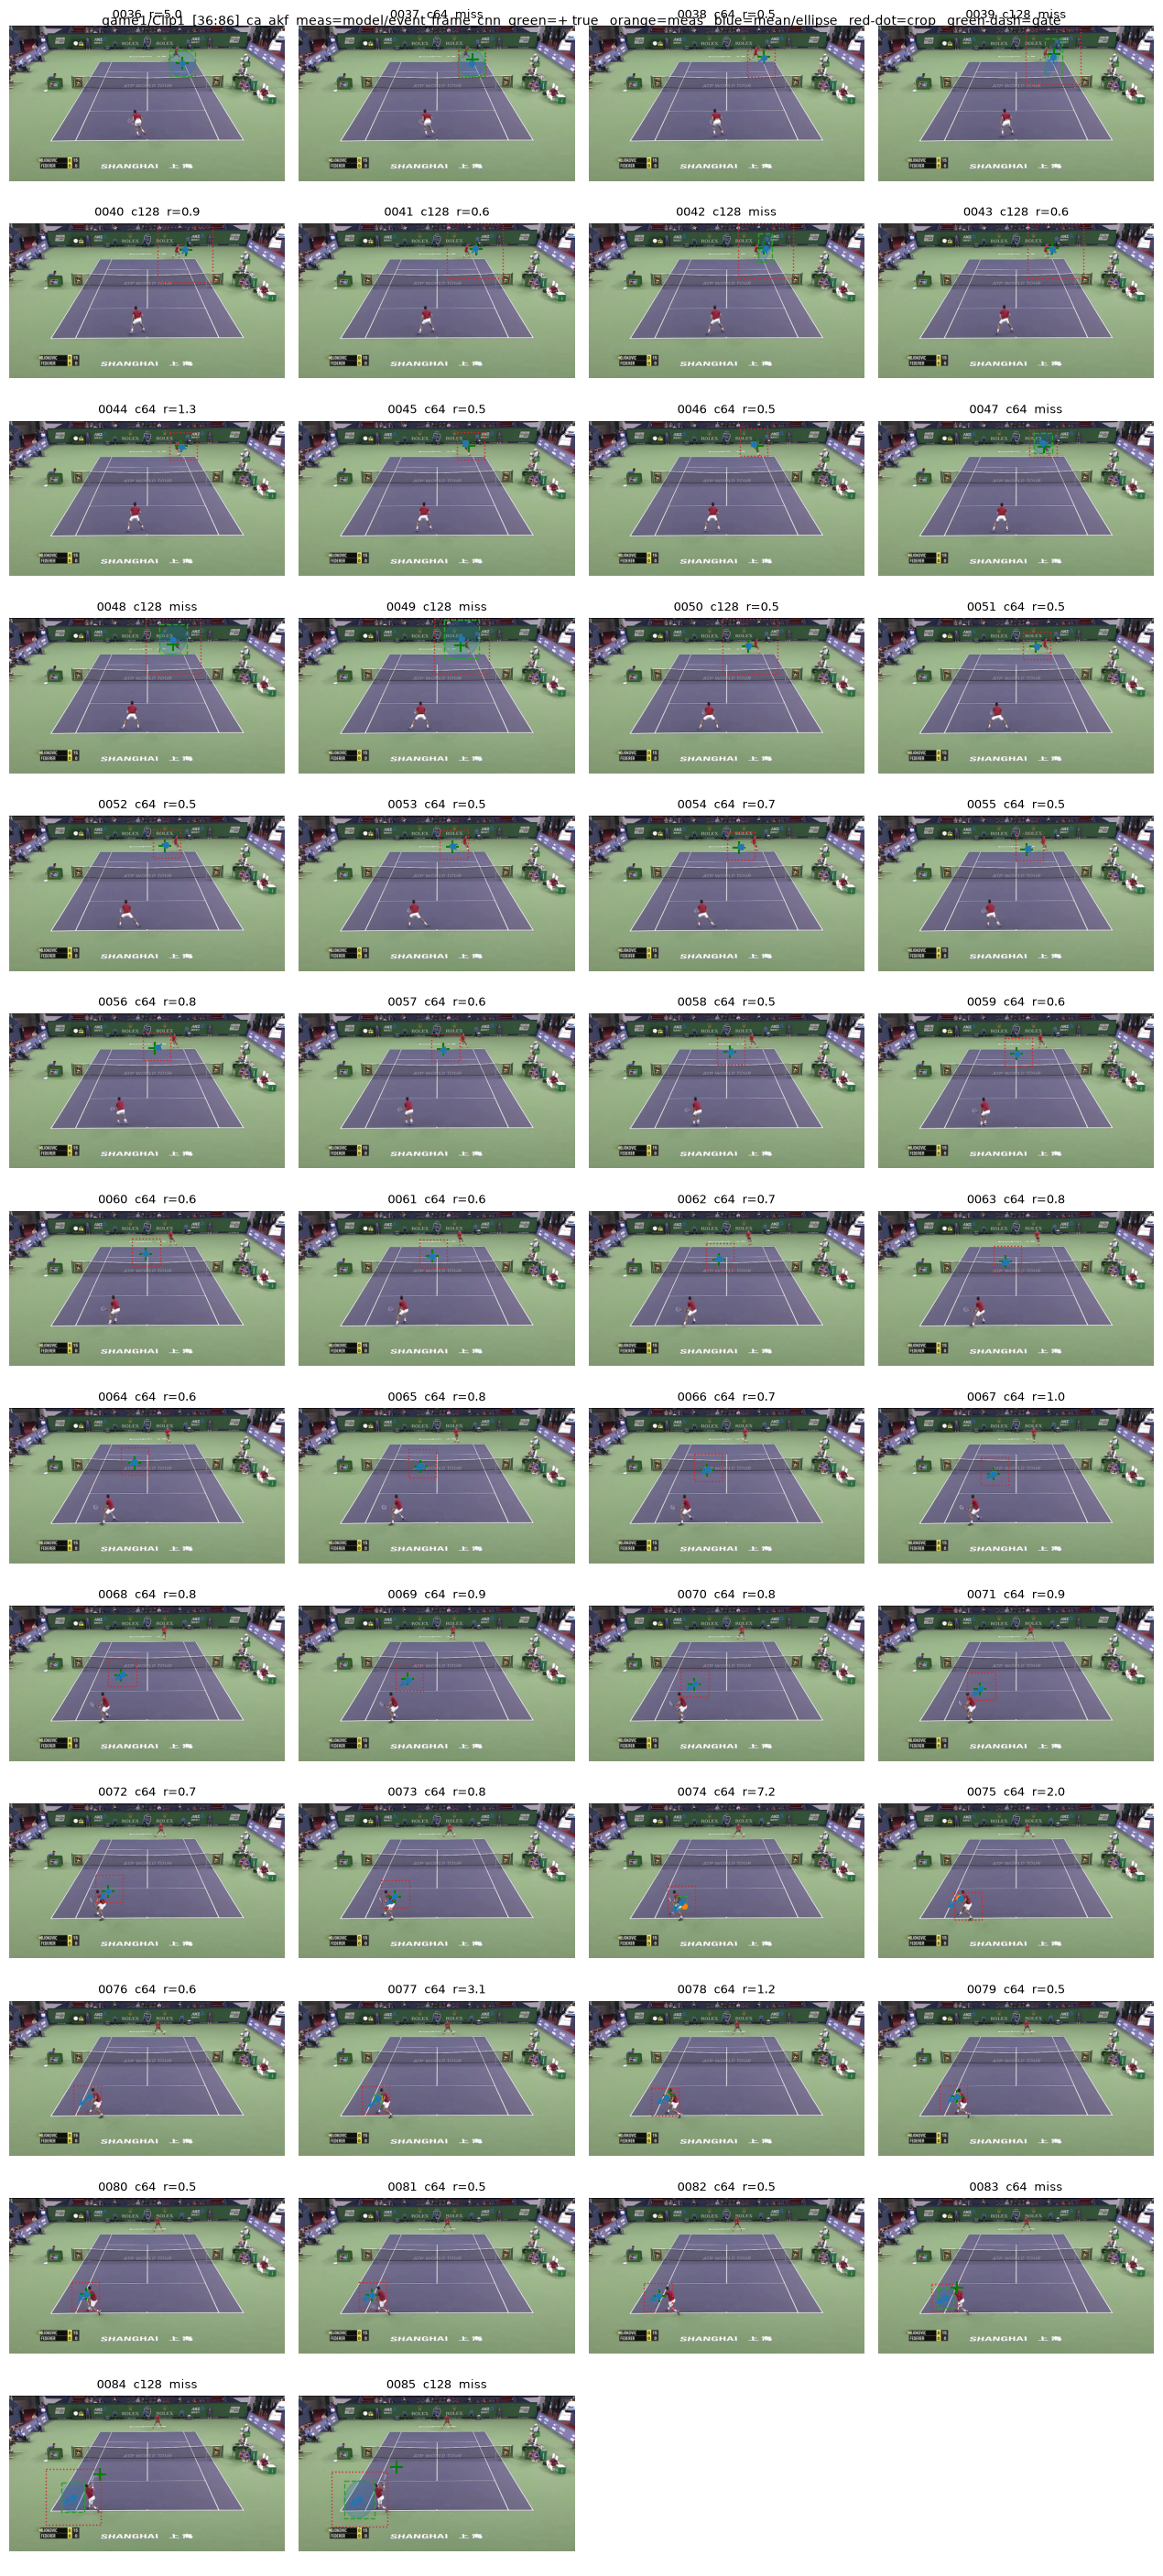

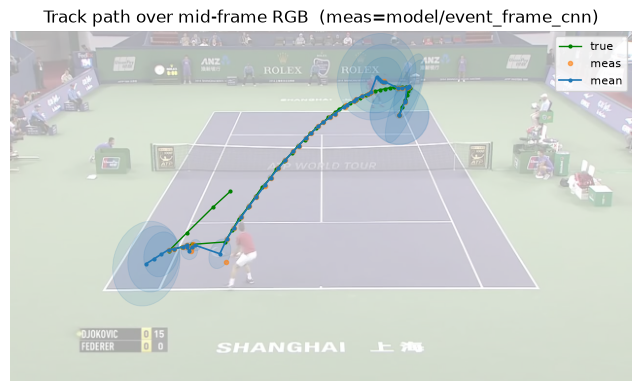

In [5]:
def cov_ellipse(mean_xy, cov_xy, n_sigma=3.0, **kwargs) -> Ellipse:
    mean_xy = np.asarray(mean_xy, dtype=np.float64).reshape(2)
    cov_xy = 0.5 * (np.asarray(cov_xy, dtype=np.float64).reshape(2, 2)
                    + np.asarray(cov_xy, dtype=np.float64).reshape(2, 2).T)
    vals, vecs = np.linalg.eigh(cov_xy)
    vals = np.clip(vals, 1e-12, None)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    angle = math.degrees(math.atan2(vecs[1, 0], vecs[0, 0]))
    return Ellipse(
        xy=(float(mean_xy[0]), float(mean_xy[1])),
        width=float(2 * n_sigma * np.sqrt(vals[0])),
        height=float(2 * n_sigma * np.sqrt(vals[1])),
        angle=float(angle),
        **kwargs,
    )


def draw_overlays(ax, t: int) -> None:
    ax.imshow(rgbs[t])
    ax.set_axis_off()
    fi = START_IDX + t
    title = f"{fi:04d}"
    if MEAS_SOURCE == "model" and crop_sizes[t] > 0:
        title += f"  c{crop_sizes[t]}"
    if detected[t] and np.isfinite(r_meas_t[t]):
        title += f"  r={r_meas_t[t]:.1f}"
    elif states[t] is not None and not detected[t] and MEAS_SOURCE == "model":
        title += "  miss"
    ax.set_title(title, fontsize=9)
    if visible[t]:
        ax.plot(true_xy[t, 0], true_xy[t, 1], "g+", ms=10, mew=1.5, label="true")
    if detected[t] and np.isfinite(meas[t]).all():
        ax.plot(meas[t, 0], meas[t, 1], "o", color="C1", ms=4, label="meas")
    if MEAS_SOURCE == "model" and crop_sizes[t] > 0:
        x0, y0 = int(crop_origins[t, 0]), int(crop_origins[t, 1])
        sz = int(crop_sizes[t])
        ax.add_patch(
            mpatches.Rectangle(
                (x0, y0), sz, sz, fill=False, edgecolor="C3", ls=":", lw=1.0
            )
        )
    st = states[t]
    if st is None:
        return
    ax.plot(st.mean[0], st.mean[1], "o", color="C0", ms=4, label="mean")
    if st.particles is not None:
        ax.scatter(
            st.particles[:, 0],
            st.particles[:, 1],
            s=4,
            c="C0",
            alpha=0.15,
            linewidths=0,
            zorder=2,
        )
    # velocity tick
    ax.annotate(
        "",
        xy=(st.mean[0] + 0.12 * st.mean[2], st.mean[1] + 0.12 * st.mean[3]),
        xytext=(st.mean[0], st.mean[1]),
        arrowprops=dict(arrowstyle="->", color="C0", lw=1.2),
    )
    ax.add_patch(
        cov_ellipse(
            st.mean[:2],
            st.cov[:2, :2],
            n_sigma=N_SIGMA,
            facecolor="C0",
            edgecolor="C0",
            alpha=0.25,
            lw=1.2,
        )
    )
    if hasattr(tracker, "gate_window"):
        x0, y0, x1, y1 = tracker.gate_window(st, n_sigma=N_SIGMA)
        ax.add_patch(
            mpatches.Rectangle(
                (x0, y0),
                x1 - x0,
                y1 - y0,
                fill=False,
                edgecolor="C2",
                ls="--",
                lw=1.0,
            )
        )


nrows = int(math.ceil(SEQ_LEN / NCOLS))
fig, axes = plt.subplots(nrows, NCOLS, figsize=(3.2 * NCOLS, 2.2 * nrows))
axes = np.atleast_2d(axes)
for t in range(nrows * NCOLS):
    ax = axes[t // NCOLS, t % NCOLS]
    if t < SEQ_LEN:
        draw_overlays(ax, t)
    else:
        ax.set_axis_off()

meas_tag = f"{MEAS_SOURCE}" + (f"/{ARCH}" if MEAS_SOURCE == "model" else "")
fig.suptitle(
    f"{key}  [{START_IDX}:{end_idx}]  {TRACKER}  meas={meas_tag}  "
    f"green=+ true   orange=meas   blue=mean/ellipse   "
    + ("red-dot=crop   " if MEAS_SOURCE == "model" else "")
    + "green-dash=gate",
    fontsize=10,
)
fig.tight_layout()
plt.show()

# Compact path summary (same window)
fig, ax = plt.subplots(figsize=(7, 4))
ax.imshow(rgbs[SEQ_LEN // 2], alpha=0.35)
ax.plot(true_xy[visible, 0], true_xy[visible, 1], "g.-", ms=4, lw=1, label="true")
det_mask = detected & np.isfinite(meas).all(axis=1)
ax.plot(meas[det_mask, 0], meas[det_mask, 1], "o", color="C1", ms=3, alpha=0.6, label="meas")
est = np.array([s.mean[:2] for s in states if s is not None])
if len(est):
    ax.plot(est[:, 0], est[:, 1], "C0.-", ms=4, lw=1.2, label="mean")
    for t, st in enumerate(states):
        if st is None:
            continue
        ax.add_patch(
            cov_ellipse(
                st.mean[:2],
                st.cov[:2, :2],
                n_sigma=N_SIGMA,
                facecolor="C0",
                edgecolor="C0",
                alpha=0.12,
                lw=0.7,
            )
        )
ax.set_xlim(0, W)
ax.set_ylim(H, 0)
ax.set_title(f"Track path over mid-frame RGB  (meas={meas_tag})")
ax.legend(loc="best", fontsize=8)
ax.set_axis_off()
fig.tight_layout()
plt.show()


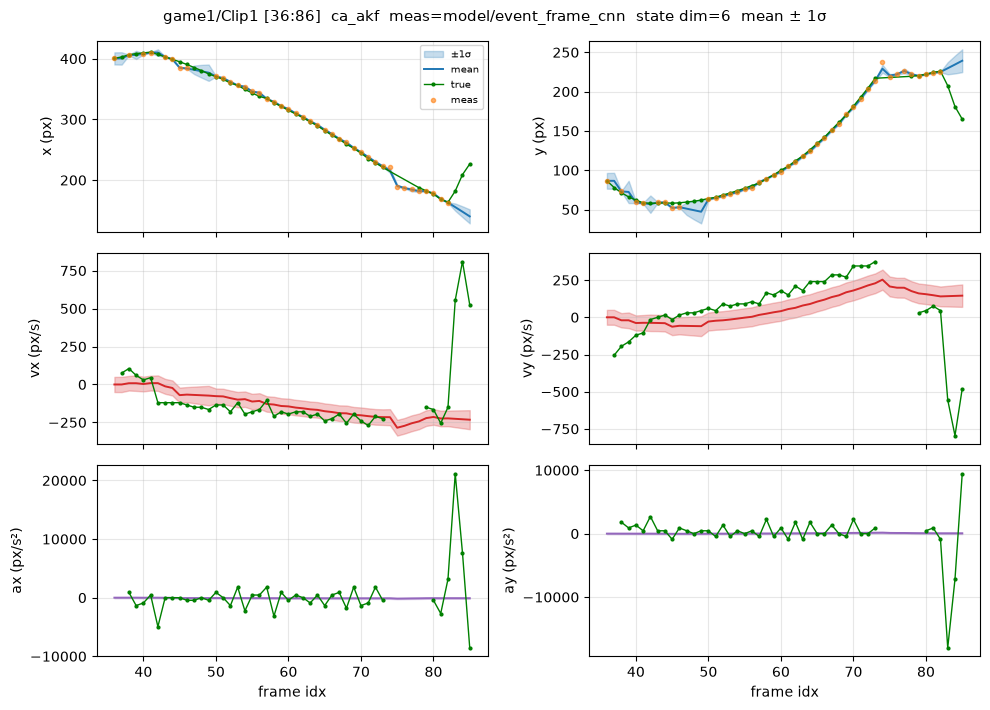

In [6]:
# Position / velocity (/ accel) uncertainty over the window (diagonal std of P)
ts = np.arange(START_IDX, end_idx)
state_dim = next((s.dim for s in states if s is not None), 4)
means = np.full((SEQ_LEN, state_dim), np.nan)
stds = np.full((SEQ_LEN, state_dim), np.nan)
for t, st in enumerate(states):
    if st is None:
        continue
    means[t] = st.mean
    stds[t] = np.sqrt(np.clip(np.diag(st.cov), 0, None))

labels_uv = ["x (px)", "y (px)", "vx (px/s)", "vy (px/s)"]
if state_dim >= 6:
    labels_uv += ["ax (px/s²)", "ay (px/s²)"]

true_vel = np.full((SEQ_LEN, 2), np.nan)
true_acc = np.full((SEQ_LEN, 2), np.nan)
dt_t = float(getattr(tracker, "dt", 1 / 30))
if visible.any():
    for t in range(1, SEQ_LEN):
        if visible[t] and visible[t - 1]:
            true_vel[t] = (true_xy[t] - true_xy[t - 1]) / dt_t
    for t in range(2, SEQ_LEN):
        if visible[t] and visible[t - 1] and visible[t - 2]:
            true_acc[t] = (true_vel[t] - true_vel[t - 1]) / dt_t

nrows = 3 if state_dim >= 6 else 2
ncols = 2
fig, axes = plt.subplots(nrows, ncols, figsize=(10, 2.4 * nrows), sharex=True)
axes_flat = np.atleast_1d(axes).ravel()

series = [
    (0, true_xy[:, 0], meas[:, 0], "C0"),
    (1, true_xy[:, 1], meas[:, 1], "C0"),
    (2, true_vel[:, 0], None, "C3"),
    (3, true_vel[:, 1], None, "C3"),
]
if state_dim >= 6:
    series += [
        (4, true_acc[:, 0], None, "C4"),
        (5, true_acc[:, 1], None, "C4"),
    ]

det_mask = detected & np.isfinite(meas).all(axis=1)
for ax, (i, truth, z, band_c) in zip(axes_flat, series):
    mu, sd = means[:, i], stds[:, i]
    ax.fill_between(ts, mu - sd, mu + sd, color=band_c, alpha=0.25, label="±1σ")
    ax.plot(ts, mu, color=band_c, lw=1.4, label="mean")
    if i < 2:
        ax.plot(ts[visible], truth[visible], "g.-", ms=4, lw=1, label="true")
        if z is not None:
            ax.plot(ts[det_mask], z[det_mask], "o", color="C1", ms=3, alpha=0.6, label="meas")
    else:
        ax.plot(ts, truth, "g.-", ms=4, lw=1, label="true Δ")
    ax.set_ylabel(labels_uv[i])
    ax.grid(True, alpha=0.3)

axes_flat[0].legend(loc="best", fontsize=7)
for ax in axes_flat[-2:]:
    ax.set_xlabel("frame idx")
meas_tag = f"{MEAS_SOURCE}" + (f"/{ARCH}" if MEAS_SOURCE == "model" else "")
fig.suptitle(
    f"{key} [{START_IDX}:{end_idx}]  {TRACKER}  meas={meas_tag}  "
    f"state dim={state_dim}  mean ± 1σ",
    fontsize=11,
)
fig.tight_layout()
plt.show()


In [7]:
# Average absolute error vs label-derived truth for every estimated state component
dt_t = float(getattr(tracker, "dt", 1.0 / 30.0))
state_dim = next((s.dim for s in states if s is not None), 4)

# Build GT kinematics from visible label positions (finite differences)
gt = np.full((SEQ_LEN, state_dim), np.nan)
gt[:, :2] = true_xy
for t in range(1, SEQ_LEN):
    if visible[t] and visible[t - 1]:
        gt[t, 2:4] = (true_xy[t] - true_xy[t - 1]) / dt_t
if state_dim >= 6:
    for t in range(2, SEQ_LEN):
        if np.isfinite(gt[t, 2:4]).all() and np.isfinite(gt[t - 1, 2:4]).all():
            gt[t, 4:6] = (gt[t, 2:4] - gt[t - 1, 2:4]) / dt_t

est = np.full((SEQ_LEN, state_dim), np.nan)
for t, st in enumerate(states):
    if st is not None:
        est[t] = st.mean

comp_names = ["x", "y", "vx", "vy"] + (["ax", "ay"] if state_dim >= 6 else [])
comp_units = ["px", "px", "px/s", "px/s"] + (["px/s²", "px/s²"] if state_dim >= 6 else [])

meas_tag = f"{MEAS_SOURCE}" + (f"/{ARCH}" if MEAS_SOURCE == "model" else "")
print(f"{TRACKER}  meas={meas_tag}  {key}[{START_IDX}:{end_idx}]  mean |error| over valid frames")
rows = []
for i, (name, unit) in enumerate(zip(comp_names, comp_units)):
    valid = np.isfinite(est[:, i]) & np.isfinite(gt[:, i])
    if i < 2:
        # position: also require label visibility
        valid &= visible
    n = int(valid.sum())
    if n == 0:
        mae = float("nan")
        rmse = float("nan")
    else:
        err = est[valid, i] - gt[valid, i]
        mae = float(np.mean(np.abs(err)))
        rmse = float(np.sqrt(np.mean(err**2)))
    rows.append((name, mae, rmse, n, unit))
    print(f"  {name:>2}:  MAE={mae:8.3f}  RMSE={rmse:8.3f}  n={n:3d}  ({unit})")

# Grouped vector errors (position / velocity / acceleration)
def _vec_rmse(cols: slice, require_vis: bool = False) -> tuple[float, int]:
    mask = np.isfinite(est[:, cols]).all(axis=1) & np.isfinite(gt[:, cols]).all(axis=1)
    if require_vis:
        mask &= visible
    n = int(mask.sum())
    if n == 0:
        return float("nan"), 0
    d = np.linalg.norm(est[mask][:, cols] - gt[mask][:, cols], axis=1)
    return float(np.mean(d)), n

pos_mae, n_pos = _vec_rmse(slice(0, 2), require_vis=True)
vel_mae, n_vel = _vec_rmse(slice(2, 4))
print(f"  pos ‖·‖:  mean={pos_mae:8.3f} px     n={n_pos:3d}")
print(f"  vel ‖·‖:  mean={vel_mae:8.3f} px/s   n={n_vel:3d}")
if state_dim >= 6:
    acc_mae, n_acc = _vec_rmse(slice(4, 6))
    print(f"  acc ‖·‖:  mean={acc_mae:8.3f} px/s²  n={n_acc:3d}")

# Detector measurement error (when a detection was accepted)
det_vis = detected & visible & np.isfinite(meas).all(axis=1)
if det_vis.any():
    m_err = np.linalg.norm(meas[det_vis] - true_xy[det_vis], axis=1)
    print(
        f"  meas ‖·‖: mean={float(m_err.mean()):.3f} px  "
        f"median={float(np.median(m_err)):.3f}  n={int(det_vis.sum())}  "
        f"(vs visible labels)"
    )


ca_akf  meas=model/event_frame_cnn  game1/Clip1[36:86]  mean |error| over valid frames
   x:  MAE=   5.607  RMSE=  16.290  n= 46  (px)
   y:  MAE=   5.535  RMSE=  14.413  n= 46  (px)
  vx:  MAE= 110.210  RMSE= 234.790  n= 44  (px/s)
  vy:  MAE= 153.548  RMSE= 229.789  n= 44  (px/s)
  ax:  MAE=1903.185  RMSE=3995.637  n= 42  (px/s²)
  ay:  MAE=1572.182  RMSE=3479.425  n= 42  (px/s²)
  pos ‖·‖:  mean=   8.186 px     n= 46
  vel ‖·‖:  mean= 197.470 px/s   n= 44
  acc ‖·‖:  mean=2594.640 px/s²  n= 42
  meas ‖·‖: mean=2.480 px  median=1.803  n=37  (vs visible labels)
